# GDBN v2: Volatility

Returns turned out to be nearly unpredictable from yesterday (notebook 03). **Volatility** (how much a stock moves, regardless of direction) is different: it **persists** (volatile days follow volatile days) and **spreads** between stocks. This is also what Diebold–Yılmaz measure.

**Daily volatility** for each of the 35 series:

$$\text{vol}_i(t) = \log\big(|r_i(t)| + 0.0001\big)$$

- $|r|$: the size of the move, ignoring direction.
- **log:** makes volatility roughly bell-shaped, which suits a **Gaussian** model.
- **0.0001:** a small floor so days with a return of exactly 0 do not give $\log(0)$.

**Variables (95 nodes):** 35 volatility + 30 news sentiment + 30 news attention.

**Inputs for each node:**
- all 95 variables **yesterday** (the dynamic Bayesian network arrows), and
- **HAR terms:** each volatility series' own average over the **past week** (5 days) and **past month** (22 days). These give the model longer memory. In DBN terms, they summarize more of the past than one day.

**Baselines** (predict tomorrow's volatility):

| Baseline | Prediction |
|---|---|
| hist_mean | the series' average volatility in training |
| ar1 | from its own volatility yesterday |
| **HAR** | from its own volatility yesterday, past week, and past month: **the standard benchmark in finance** |

**Steps:** pairs and standardization → one lasso per node (λ on validation) → network → refit with σ → stability → graph checks → predictions vs baselines → save → final test (run once at the end).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.linear_model import lasso_path, Lasso
from gdbn_utils import (load_data, standardizer, evaluate, summarize, dm_report,
                        volatility_dataset, har_features, RESULTS, Z90)

pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

wide, split, info = load_data()
SENT, ATTN, STOCKS, SECTOR = info["SENT"], info["ATTN"], info["STOCKS"], info["SECTOR"]
ticker, kind = info["ticker"], info["kind"]

data, VOL = volatility_dataset(wide, info)
VARS = list(data.columns)
HAR = har_features(data, VOL)
print(f"{len(VOL)} volatility + {len(SENT)} sentiment + {len(ATTN)} attention = {len(VARS)} nodes")

35 volatility + 30 sentiment + 30 attention = 95 nodes


## 1. Pairs and standardization

- $X_{\text{lag}}$: all 95 variables on day $t-1$.
- $X_{\text{HAR}}$: each volatility series' week and month averages, using days up to $t-1$ only.
- $Y$: all 95 variables on day $t$.

The first 22 days are dropped (the month average needs 22 days of history). Standardization uses **training statistics only**.

In [2]:
X_lag = data.shift(1).add_suffix("@t-1")
X_har = HAR.shift(1)
X_all = pd.concat([X_lag, X_har], axis=1)
Y = data.copy()

keep = X_all.notna().all(axis=1)
X_all, Y = X_all[keep], Y[keep]
labels = split.loc[Y.index]
tr, va = (labels == "train").values, (labels == "validation").values
LAG_COLS, HAR_COLS = list(X_lag.columns), list(X_har.columns)

mu_x, sd_x = standardizer(X_all[tr])
mu_y, sd_y = standardizer(Y[tr])
Xz = (X_all - mu_x) / sd_x
Yz = (Y - mu_y) / sd_y
print(f"train pairs: {tr.sum()}, validation pairs: {va.sum()}, inputs per node: {X_all.shape[1]} "
      f"({len(LAG_COLS)} lagged + {len(HAR_COLS)} HAR terms)")

train pairs: 1741, validation pairs: 251, inputs per node: 165 (95 lagged + 70 HAR terms)


## 2. Baselines

In [3]:
y_val = Y.loc[va, VOL]

def ols_predict(cols_for):
    out = {}
    for c in VOL:
        A = np.column_stack([np.ones(len(X_all)), X_all[cols_for(c)].values])
        coef, *_ = np.linalg.lstsq(A[tr], Y[c].values[tr], rcond=None)
        resid = Y[c].values[tr] - A[tr] @ coef
        out[c] = (A @ coef, resid.std(ddof=A.shape[1]))
    pred = pd.DataFrame({c: v[0] for c, v in out.items()}, index=Y.index)
    sig = pd.Series({c: v[1] for c, v in out.items()})
    return pred, sig

base_preds, base_sig = {}, {}
base_preds["hist_mean"] = pd.DataFrame(np.tile(Y.loc[tr, VOL].mean().values, (len(Y), 1)), index=Y.index, columns=VOL)
base_sig["hist_mean"] = Y.loc[tr, VOL].std()
base_preds["ar1"], base_sig["ar1"] = ols_predict(lambda c: [f"{c}@t-1"])
base_preds["HAR"], base_sig["HAR"] = ols_predict(lambda c: [f"{c}@t-1", f"{c}_week", f"{c}_month"])

bench_hist = ((y_val - base_preds["hist_mean"].loc[va]) ** 2).mean()
bench_har = ((y_val - base_preds["HAR"].loc[va]) ** 2).mean()

## 3. One lasso per node, λ chosen on validation

Two versions, to see what the HAR terms add:
- **GDBN (lag-1):** inputs = the 95 variables yesterday.
- **GDBN + HAR:** inputs = the 95 variables yesterday + each volatility series' week and month averages.

For each node: fit the lasso path on training, pick the λ with the lowest validation error (**best**) and the sparsest λ within one standard error of it (**1-SE**).

In [4]:
def fit_lasso_gdbn(input_cols):
    idx = [X_all.columns.get_loc(c) for c in input_cols]
    Xtr, Xva = Xz.values[tr][:, idx], Xz.values[va][:, idx]
    xm = Xtr.mean(axis=0)
    Xall_c = Xz.values[:, idx] - xm
    W = {"best": np.zeros((len(VARS), len(idx))), "1se": np.zeros((len(VARS), len(idx)))}
    alpha = {"best": np.zeros(len(VARS)), "1se": np.zeros(len(VARS))}
    pred = {"best": {}, "1se": {}}   # shrunk-lasso predictions, back in original units
    sigma = {"best": {}, "1se": {}}
    for i, target in enumerate(VARS):
        y_tr, y_va = Yz[target].values[tr], Yz[target].values[va]
        ym = y_tr.mean()
        alphas, coefs, _ = lasso_path(Xtr - xm, y_tr - ym, n_alphas=60, eps=1e-3)
        sq = (y_va[:, None] - (ym + (Xva - xm) @ coefs)) ** 2
        mse = sq.mean(axis=0)
        k_best = int(np.argmin(mse))
        se = sq[:, k_best].std(ddof=1) / np.sqrt(len(y_va))
        k_1se = int(np.min(np.where(mse <= mse[k_best] + se)[0]))
        for name, k in [("best", k_best), ("1se", k_1se)]:
            W[name][i], alpha[name][i] = coefs[:, k], alphas[k]
            pz = ym + Xall_c @ coefs[:, k]
            pred[name][target] = pz * sd_y[target] + mu_y[target]
            sigma[name][target] = (Yz[target].values[tr] - pz[tr]).std(ddof=1) * sd_y[target]
    return {"cols": list(input_cols), "W": W, "alpha": alpha,
            "pred": {k: pd.DataFrame(v, index=Y.index) for k, v in pred.items()},
            "sigma": {k: pd.Series(v) for k, v in sigma.items()}}

gdbn = {"lag1": fit_lasso_gdbn(LAG_COLS), "lag1+HAR": fit_lasso_gdbn(LAG_COLS + HAR_COLS)}
for v, m in gdbn.items():
    for name in ["best", "1se"]:
        print(f"GDBN {v:<9} {name:>4} λ: {int((m['W'][name] != 0).sum()):,} edges")

GDBN lag1      best λ: 3,308 edges
GDBN lag1       1se λ: 303 edges
GDBN lag1+HAR  best λ: 3,563 edges
GDBN lag1+HAR   1se λ: 324 edges


## 4. Predictions: lasso (shrunk) and refit, with σ

Two ways to turn the lasso into forecasts:
- **lasso:** use the lasso's own weights. They are **shrunk** toward 0, which often predicts *better* out of sample (less overfitting).
- **refit:** use the lasso only to **choose** the inputs, then refit ordinary regression on them (unshrunk weights). Cleaner weights, but it can overfit when a node keeps many inputs.

The training residuals give each node's $\sigma$, so every forecast comes with a 90% range (± 1.645 σ).

In [5]:
def refit_and_predict(model, which):
    cols = model["cols"]
    idx = [X_all.columns.get_loc(c) for c in cols]
    Xall_z = Xz.values[:, idx]
    preds, sigmas, Wr = {}, {}, np.zeros_like(model["W"][which])
    for i, target in enumerate(VARS):
        sel = np.nonzero(model["W"][which][i])[0]
        A = np.column_stack([np.ones(len(Xall_z)), Xall_z[:, sel]])
        coef, *_ = np.linalg.lstsq(A[tr], Yz[target].values[tr], rcond=None)
        Wr[i, sel] = coef[1:]
        resid = Yz[target].values[tr] - A[tr] @ coef
        preds[target] = (A @ coef) * sd_y[target] + mu_y[target]           # back to vol units
        sigmas[target] = resid.std(ddof=A.shape[1]) * sd_y[target]
    return pd.DataFrame(preds, index=Y.index), pd.Series(sigmas), Wr

fitted = {}
for v in gdbn:
    for which in ["best", "1se"]:
        fitted[f"GDBN {v} lasso ({which})"] = (gdbn[v]["pred"][which], gdbn[v]["sigma"][which], gdbn[v]["W"][which])
        fitted[f"GDBN {v} refit ({which})"] = refit_and_predict(gdbn[v], which)
print("models:", list(fitted))

models: ['GDBN lag1 lasso (best)', 'GDBN lag1 refit (best)', 'GDBN lag1 lasso (1se)', 'GDBN lag1 refit (1se)', 'GDBN lag1+HAR lasso (best)', 'GDBN lag1+HAR refit (best)', 'GDBN lag1+HAR lasso (1se)', 'GDBN lag1+HAR refit (1se)']


## 5. Predictions vs baselines (validation 2022)

- **r2_os vs hist:** out-of-sample $R^2$ against the historical mean.
- **r2_os vs HAR:** against the standard benchmark. **Positive = beats HAR.**
- **coverage90:** does the 90% range contain the actual volatility 90% of the time?

In [6]:
rows = {}
errors = {}
for name, p in base_preds.items():
    ev = evaluate(y_val, p.loc[va], base_sig[name], bench_hist)
    ev["r2_os vs HAR"] = 1 - ev["mse"] / bench_har
    rows[name], errors[name] = summarize(ev), y_val - p.loc[va]
for name, (p, sig, _) in fitted.items():
    ev = evaluate(y_val, p.loc[va, VOL], sig[VOL], bench_hist)
    ev["r2_os vs HAR"] = 1 - ev["mse"] / bench_har
    rows[name], errors[name] = summarize(ev), y_val - p.loc[va, VOL]

table = pd.DataFrame(rows).T.drop(columns=["direction"]).rename(columns={"r2_os": "r2_os vs hist"})
table[["mse", "r2_os vs hist", "r2_os vs HAR", "coverage90"]]

,mse,r2_os vs hist,r2_os vs HAR,coverage90
hist_mean,1.3379,0.0000,-0.1247,0.9237
ar1,1.3158,0.0150,-0.1054,0.9191
HAR,1.1937,0.1003,0.0000,0.9234
GDBN lag1 lasso (best),1.2516,0.0621,-0.0493,0.9166
GDBN lag1 refit (best),1.2710,0.0472,-0.0655,0.9114
GDBN lag1 lasso (1se),1.3151,0.0160,-0.1037,0.9229
GDBN lag1 refit (1se),1.2857,0.0362,-0.0778,0.9246
GDBN lag1+HAR lasso (best),1.1822,0.1108,0.0097,0.9218
GDBN lag1+HAR refit (best),1.2087,0.0901,-0.0127,0.9139
GDBN lag1+HAR lasso (1se),1.2633,0.0516,-0.0586,0.9282


In [7]:
print("Diebold–Mariano tests vs HAR (the benchmark to beat):")
for name in fitted:
    print(" ", dm_report(name, "HAR", errors[name], errors["HAR"]))
print()
print(" ", dm_report("HAR", "hist_mean", errors["HAR"], errors["hist_mean"]))

Diebold–Mariano tests vs HAR (the benchmark to beat):
  GDBN lag1 lasso (best) vs HAR: mean loss diff = +5.78e-02, t = +6.15, p = 0.000 -> HAR is better, significant (p < 0.05)
  GDBN lag1 refit (best) vs HAR: mean loss diff = +7.72e-02, t = +6.11, p = 0.000 -> HAR is better, significant (p < 0.05)
  GDBN lag1 lasso (1se) vs HAR: mean loss diff = +1.21e-01, t = +7.25, p = 0.000 -> HAR is better, significant (p < 0.05)
  GDBN lag1 refit (1se) vs HAR: mean loss diff = +9.19e-02, t = +7.31, p = 0.000 -> HAR is better, significant (p < 0.05)
  GDBN lag1+HAR lasso (best) vs HAR: mean loss diff = -1.15e-02, t = -2.37, p = 0.018 -> GDBN lag1+HAR lasso (best) is better, significant (p < 0.05)
  GDBN lag1+HAR refit (best) vs HAR: mean loss diff = +1.50e-02, t = +1.39, p = 0.163 -> difference not significant
  GDBN lag1+HAR lasso (1se) vs HAR: mean loss diff = +6.95e-02, t = +5.22, p = 0.000 -> HAR is better, significant (p < 0.05)
  GDBN lag1+HAR refit (1se) vs HAR: mean loss diff = +1.29e-02, 

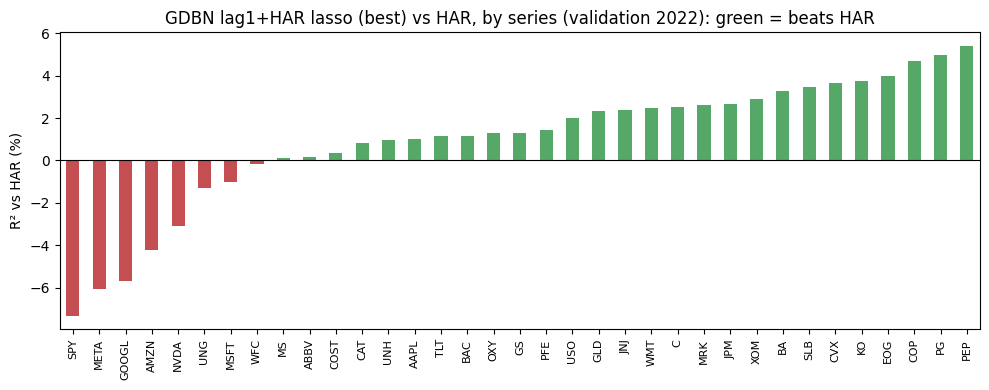

Beats HAR on 27 of 35 series


In [8]:
# Which series benefit most from the network? (GDBN lag1+HAR, best λ, vs HAR)
best_name = "GDBN lag1+HAR lasso (best)"
p_best = fitted[best_name][0].loc[va, VOL]
gain = (1 - ((y_val - p_best) ** 2).mean() / bench_har).sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
gain.mul(100).plot.bar(ax=ax, color=np.where(gain > 0, "#55a868", "#c44e52"))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("R² vs HAR (%)"); ax.set_title(f"{best_name} vs HAR, by series (validation 2022): green = beats HAR")
ax.set_xticklabels([c.replace("_vol", "") for c in gain.index], rotation=90, fontsize=8)
plt.tight_layout(); plt.show()
print(f"Beats HAR on {(gain > 0).sum()} of {len(gain)} series")

## 6. The network

A nonzero weight from input $j$ to node $i$ is an arrow. Inputs come in three **roles**:
- **yesterday:** a variable's value on day $t-1$.
- **week avg / month avg:** a volatility series' average over the past 5 or 22 days.

An edge is **own** if the input is the node's own variable (its memory) and **cross** if it comes from a different variable (a spillover or news link). Results are shown for both λ settings.

In [9]:
def edge_table(model, which):
    Wm = model["W"][which]
    i_idx, j_idx = np.nonzero(Wm)
    E = pd.DataFrame({"source": [model["cols"][j] for j in j_idx], "target (t)": [VARS[i] for i in i_idx],
                      "weight": Wm[i_idx, j_idx]})
    E["src_var"] = (E["source"].str.replace("@t-1", "", regex=False)
                    .str.replace("_week", "", regex=False).str.replace("_month", "", regex=False))
    E["src_role"] = np.select([E["source"].str.endswith("_week"), E["source"].str.endswith("_month")],
                              ["week avg", "month avg"], "yesterday")
    E["link"] = np.where(E["src_var"] == E["target (t)"], "own", "cross")
    E["src_tk"], E["dst_tk"] = E["src_var"].map(ticker), E["target (t)"].map(ticker)
    E["src_kind"], E["dst_kind"] = E["src_var"].map(kind), E["target (t)"].map(kind)
    return E

m = gdbn["lag1+HAR"]
edges_tbl = {which: edge_table(m, which) for which in ["best", "1se"]}
for which, E in edges_tbl.items():
    print(f"===== {which} λ: {len(E)} edges =====")
    print(E.assign(type=E["src_kind"] + " → " + E["dst_kind"]).groupby(["type", "link", "src_role"]).size()
           .unstack(fill_value=0).to_string(), "\n")

===== best λ: 3563 edges =====
src_role           month avg  week avg  yesterday
type        link                                 
attn → attn cross          0         0        404
            own            0         0         30
attn → sent cross          0         0        240
attn → vol  cross          0         0        133
sent → attn cross          0         0        335
sent → sent cross          0         0        226
            own            0         0         29
sent → vol  cross          0         0        153
vol → attn  cross        271       248        320
vol → sent  cross        186       196        213
vol → vol   cross        146       251        140
            own           19        17          6 

===== 1se λ: 324 edges =====
src_role           month avg  week avg  yesterday
type        link                                 
attn → attn cross          0         0         37
            own            0         0         21
attn → sent cross          0         0

In [10]:
# Strongest CROSS edges into volatility (spillovers), 1-SE λ (falls back to best λ if none)
E = edges_tbl["1se"]
cv = E[(E["link"] == "cross") & (E["dst_kind"] == "vol")]
if cv.empty:
    E = edges_tbl["best"]; cv = E[(E["link"] == "cross") & (E["dst_kind"] == "vol")]
    print("(no cross edges into volatility at 1-SE λ; showing best λ)")
cv.reindex(cv["weight"].abs().sort_values(ascending=False).index)[["source", "target (t)", "src_role", "weight"]].head(20)

,source,target (t),src_role,weight
50,XOM_vol_month,OXY_vol,month avg,0.1012
81,EOG_vol_month,SPY_vol,month avg,0.0699
31,XOM_vol_week,META_vol,week avg,0.0663
34,GOOGL_vol_month,META_vol,month avg,0.0642
22,META_vol_week,AMZN_vol,week avg,0.0599
45,XOM_vol_month,CVX_vol,month avg,0.0506
47,XOM_vol_month,SLB_vol,month avg,0.0402
53,SPY_vol_week,PG_vol,week avg,0.0373
54,UNH_vol_month,PG_vol,month avg,0.0361
43,SLB_vol_month,XOM_vol,month avg,0.0356


## 7. Check the graph (upstream)

Does the structure make economic sense? Checked on both graphs.

In [11]:
energy = [t for t in STOCKS if SECTOR[t] == "Energy"]
pairs = [(a, b) for a in STOCKS for b in STOCKS if a != b]
chance = np.mean([SECTOR[a] == SECTOR[b] for a, b in pairs])

def upstream(E, name):
    cross = E[E["link"] == "cross"]
    print(f"===== {name} λ =====")
    vv = cross[(cross["src_kind"] == "vol") & (cross["dst_kind"] == "vol")
               & cross["src_tk"].isin(STOCKS) & cross["dst_tk"].isin(STOCKS)]
    same = (vv["src_tk"].map(SECTOR) == vv["dst_tk"].map(SECTOR)).mean() if len(vv) else float("nan")
    print(f"(a) stock→stock volatility spillover edges: {len(vv)}"
          + (f"; same-sector share {same:.0%} (chance: {chance:.0%})" if len(vv) else ""))
    print(f"    by role: {vv['src_role'].value_counts().to_dict()}")
    mk = cross[(cross["src_tk"] == "SPY") & (cross["src_kind"] == "vol") & (cross["dst_kind"] == "vol")]
    print(f"(b) market (SPY) volatility → other volatility: {len(mk)} edges")
    oil = cross[(cross["src_tk"] == "USO") & (cross["src_kind"] == "vol") & (cross["dst_kind"] == "vol")]
    print(f"(c) oil volatility → other volatility: {len(oil)} edges, of which to energy stocks: {oil['dst_tk'].isin(energy).sum()}")
    news = cross[cross["src_kind"].isin(["attn", "sent"]) & (cross["dst_kind"] == "vol")]
    own_attn = news[(news["src_kind"] == "attn") & (news["src_tk"] == news["dst_tk"])]
    print(f"(d) news → next-day volatility: {len(news)} edges; own attention → own volatility: {len(own_attn)} of {len(STOCKS)} stocks")
    mem = E[(E["link"] == "own") & (E["dst_kind"] == "vol")]
    print(f"(e) volatility nodes using their own past: {mem['target (t)'].nunique()} of {len(VOL)}; "
          f"by role: {mem['src_role'].value_counts().to_dict()}\n")

for which in ["best", "1se"]:
    upstream(edges_tbl[which], which)

===== best λ =====
(a) stock→stock volatility spillover edges: 393; same-sector share 25% (chance: 15%)
    by role: {'week avg': 183, 'month avg': 117, 'yesterday': 93}
(b) market (SPY) volatility → other volatility: 11 edges
(c) oil volatility → other volatility: 11 edges, of which to energy stocks: 2
(d) news → next-day volatility: 286 edges; own attention → own volatility: 5 of 30 stocks
(e) volatility nodes using their own past: 28 of 35; by role: {'month avg': 19, 'week avg': 17, 'yesterday': 6}

===== 1se λ =====
(a) stock→stock volatility spillover edges: 55; same-sector share 53% (chance: 15%)
    by role: {'month avg': 29, 'week avg': 26}
(b) market (SPY) volatility → other volatility: 5 edges
(c) oil volatility → other volatility: 0 edges, of which to energy stocks: 0
(d) news → next-day volatility: 2 edges; own attention → own volatility: 0 of 30 stocks
(e) volatility nodes using their own past: 12 of 35; by role: {'month avg': 10, 'week avg': 4}



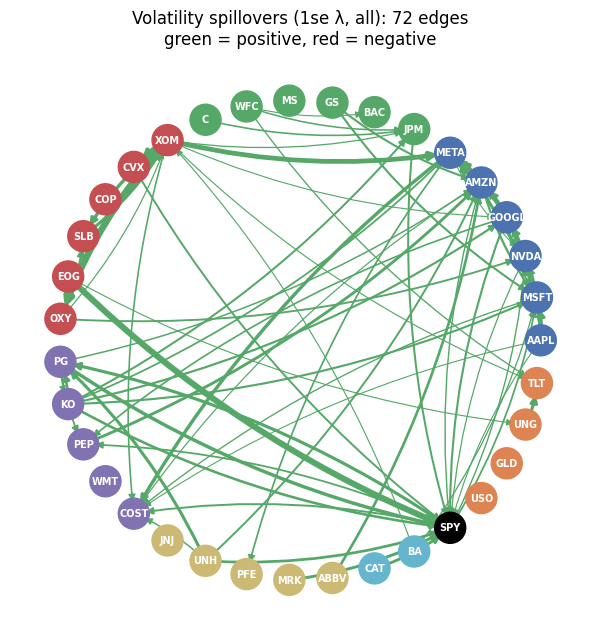

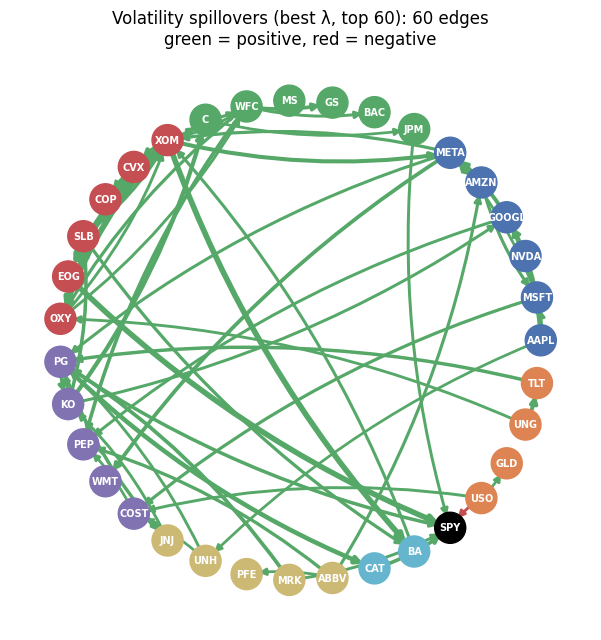

In [12]:
# Draw the volatility spillover network: cross edges between volatility nodes (any role)
colors = {"Tech": "#4c72b0", "Banks": "#55a868", "Energy": "#c44e52", "Staples": "#8172b2",
          "Healthcare": "#ccb974", "Industrials": "#64b5cd", "Market": "black", "Commodities/Rates": "#dd8452"}
for which, top in [("1se", None), ("best", 60)]:
    E = edges_tbl[which]
    sub = E[(E["link"] == "cross") & (E["src_kind"] == "vol") & (E["dst_kind"] == "vol")]
    sub = sub.groupby(["src_tk", "dst_tk"], as_index=False)["weight"].sum()   # combine yesterday/week/month
    if top:
        sub = sub.reindex(sub["weight"].abs().sort_values(ascending=False).index).head(top)
    net = nx.DiGraph(); net.add_nodes_from(ticker(c) for c in VOL)
    for _, r in sub.iterrows():
        net.add_edge(r["src_tk"], r["dst_tk"], weight=r["weight"])
    pos = nx.circular_layout(net)
    plt.figure(figsize=(7.5, 7.5))
    nx.draw_networkx_nodes(net, pos, node_color=[colors[SECTOR[n]] for n in net.nodes], node_size=500)
    nx.draw_networkx_labels(net, pos, font_size=7, font_color="white", font_weight="bold")
    if net.number_of_edges():
        wmax = max(abs(net[u][v]["weight"]) for u, v in net.edges)
        nx.draw_networkx_edges(net, pos, edge_color=["#c44e52" if net[u][v]["weight"] < 0 else "#55a868" for u, v in net.edges],
                               width=[0.8 + 4 * abs(net[u][v]["weight"]) / wmax for u, v in net.edges], arrowsize=10,
                               connectionstyle="arc3,rad=0.1")
    label = f"top {top}" if top else "all"
    plt.title(f"Volatility spillovers ({which} λ, {label}): {net.number_of_edges()} edges\ngreen = positive, red = negative")
    plt.axis("off"); plt.show()

## 8. Stability selection (1-SE λ)

Refit on 50 random halves of the training period (in 1-month blocks). Edges chosen in **≥ 70%** of refits are stable. (About a minute.)

In [13]:
N_RESAMPLES, BLOCK = 50, 21
Wm = m["W"]["1se"]
cols = m["cols"]; idx = [X_all.columns.get_loc(c) for c in cols]
Xtr_full = Xz.values[tr][:, idx]
n_tr = tr.sum()
blocks = np.array_split(np.arange(n_tr), int(np.ceil(n_tr / BLOCK)))
freq = np.zeros_like(Wm)
for _ in range(N_RESAMPLES):
    rows_ = np.concatenate([blocks[b] for b in rng.choice(len(blocks), size=len(blocks) // 2, replace=False)])
    for i, target in enumerate(VARS):
        fit = Lasso(alpha=m["alpha"]["1se"][i], max_iter=5000).fit(Xtr_full[rows_], Yz[target].values[tr][rows_])
        freq[i] += fit.coef_ != 0
freq /= N_RESAMPLES

E = edges_tbl["1se"].copy()
i_idx, j_idx = np.nonzero(Wm)
E["stability"] = freq[i_idx, j_idx]
summary = E.groupby(["dst_kind", "link"])["stability"].agg(edges="size", stable_share=lambda s: (s >= 0.7).mean())
print(summary.round(2).to_string())
print("\nMost stable cross edges into volatility:")
E[(E["dst_kind"] == "vol") & (E["link"] == "cross")] \
    .sort_values(["stability", "weight"], ascending=False)[["source", "target (t)", "src_role", "weight", "stability"]].head(15)

                edges  stable_share
dst_kind link                      
attn     cross     89          0.34
         own       21          0.90
sent     cross    109          0.32
         own       10          0.90
vol      cross     81          0.10
         own       14          0.36

Most stable cross edges into volatility:


,source,target (t),src_role,weight,stability
81,EOG_vol_month,SPY_vol,month avg,0.0699,0.92
22,META_vol_week,AMZN_vol,week avg,0.0599,0.88
31,XOM_vol_week,META_vol,week avg,0.0663,0.84
90,ABBV_attn@t-1,TLT_vol,yesterday,0.0316,0.80
50,XOM_vol_month,OXY_vol,month avg,0.1012,0.78
78,MRK_vol_week,SPY_vol,week avg,0.0334,0.78
77,PG_vol_week,SPY_vol,week avg,0.0329,0.76
28,ABBV_vol_month,AMZN_vol,month avg,0.0283,0.72
54,UNH_vol_month,PG_vol,month avg,0.0361,0.66
93,UNG_vol_month,TLT_vol,month avg,0.0347,0.66


## 9. Save results

In [14]:
RESULTS.mkdir(parents=True, exist_ok=True)
for v, mm in gdbn.items():
    for which in ["best", "1se"]:
        pd.DataFrame(mm["W"][which], index=VARS, columns=mm["cols"]).to_csv(RESULTS / f"vol_gdbn_W_{v.replace('+', '_')}_{which}.csv")
for which, Et in edges_tbl.items():
    Et.drop(columns=["src_tk", "dst_tk"]).to_csv(RESULTS / f"vol_gdbn_edges_lag1_HAR_{which}.csv", index=False)
E.drop(columns=["src_tk", "dst_tk"]).to_csv(RESULTS / "vol_gdbn_edges_lag1_HAR_1se_stability.csv", index=False)
table.to_csv(RESULTS / "vol_gdbn_validation_results.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
